In [48]:
import pandas as pd
import numpy as np

train_data = pd.read_csv(
    "/content/glaucoma_data/ORIGA_train.csv"
)

test_data = pd.read_csv(
    "/content/glaucoma_data/ORIGA_test.csv"
)

print("Training data:")
print(train_data.head())

print("\nTesting data:")
print(test_data.head())

print("\nColumns:")
print(train_data.columns)

Training data:
             ImageName  glaucoma
0  ORIGA/train/125.jpg         0
1  ORIGA/train/075.jpg         0
2  ORIGA/train/169.jpg         0
3  ORIGA/train/227.jpg         0
4  ORIGA/train/038.jpg         0

Testing data:
            ImageName  glaucoma
0  ORIGA/test/517.jpg         0
1  ORIGA/test/333.jpg         0
2  ORIGA/test/388.jpg         0
3  ORIGA/test/315.jpg         0
4  ORIGA/test/074.jpg         0

Columns:
Index(['ImageName', 'glaucoma'], dtype='object')


In [49]:
# A1 - Function definitions

def encode_data(data):
    # Convert categorical columns into numbers
    data = data.copy()

    for column in data.columns:
        if data[column].dtype == "object":
            data[column] = pd.factorize(data[column])[0]

    return data


def impute_data(data, method="mean"):
    # Fill missing values
    data = data.copy()

    for column in data.columns:

        if method == "mean":
            data[column] = data[column].fillna(
                data[column].mean()
            )

        elif method == "median":
            data[column] = data[column].fillna(
                data[column].median()
            )

        elif method == "mode":
            data[column] = data[column].fillna(
                data[column].mode()[0]
            )

    return data


def calculate_distance(point1, point2, metric="euclidean"):

    if metric == "euclidean":
        return np.sqrt(
            np.sum((point1 - point2) ** 2)
        )

    elif metric == "manhattan":
        return np.sum(
            np.abs(point1 - point2)
        )


def bubble_sort(distances):

    distances = distances.copy()

    for i in range(len(distances)):

        for j in range(
            len(distances) - i - 1
        ):

            if distances[j][0] > distances[j + 1][0]:

                distances[j], distances[j + 1] = (
                    distances[j + 1],
                    distances[j]
                )

    return distances


def selection_sort(distances):

    distances = distances.copy()

    for i in range(len(distances)):

        minimum = i

        for j in range(i + 1, len(distances)):

            if distances[j][0] < distances[minimum][0]:
                minimum = j

        distances[i], distances[minimum] = (
            distances[minimum],
            distances[i]
        )

    return distances


def insertion_sort(distances):

    distances = distances.copy()

    for i in range(1, len(distances)):

        current = distances[i]
        j = i - 1

        while j >= 0 and distances[j][0] > current[0]:

            distances[j + 1] = distances[j]
            j = j - 1

        distances[j + 1] = current

    return distances


def sort_distances(distances, method="bubble"):

    if method == "bubble":
        return bubble_sort(distances)

    elif method == "selection":
        return selection_sort(distances)

    elif method == "insertion":
        return insertion_sort(distances)


def identify_neighbors(
    X_train,
    y_train,
    test_point,
    k=3,
    metric="euclidean",
    sorting_method="bubble"
):

    distances = []

    for i in range(len(X_train)):

        distance = calculate_distance(
            X_train[i],
            test_point,
            metric
        )

        distances.append(
            (distance, y_train[i])
        )

    distances = sort_distances(
        distances,
        sorting_method
    )

    return distances[:k]


def assign_class(neighbors):

    votes = {}

    for distance, label in neighbors:

        if label not in votes:
            votes[label] = 0

        votes[label] += 1

    return max(
        votes,
        key=votes.get
    )

In [50]:
# A1(a) Encoding

encoded_train = encode_data(train_data)

print("Encoding completed.")
print(encoded_train.head())

Encoding completed.
   ImageName  glaucoma
0          0         0
1          1         0
2          2         0
3          3         0
4          4         0


In [51]:
# A1(b) Data Imputation

mean_data = impute_data(
    encoded_train,
    method="mean"
)

median_data = impute_data(
    encoded_train,
    method="median"
)

mode_data = impute_data(
    encoded_train,
    method="mode"
)

print("Mean imputation completed.")
print("Median imputation completed.")
print("Mode imputation completed.")

Mean imputation completed.
Median imputation completed.
Mode imputation completed.


In [52]:
# A1(c) Distance Calculation

point1 = np.array([1, 2, 3])
point2 = np.array([4, 5, 6])

euclidean_distance = calculate_distance(
    point1,
    point2,
    "euclidean"
)

manhattan_distance = calculate_distance(
    point1,
    point2,
    "manhattan"
)

print("Euclidean distance:", euclidean_distance)
print("Manhattan distance:", manhattan_distance)

Euclidean distance: 5.196152422706632
Manhattan distance: 9


In [53]:
# A1(d) Sorting

distances = [
    (0.8, "Normal"),
    (0.2, "Glaucoma"),
    (0.5, "Normal"),
    (0.1, "Glaucoma")
]

bubble_result = sort_distances(
    distances,
    "bubble"
)

selection_result = sort_distances(
    distances,
    "selection"
)

insertion_result = sort_distances(
    distances,
    "insertion"
)

print("Bubble Sort:")
print(bubble_result)

print("\nSelection Sort:")
print(selection_result)

print("\nInsertion Sort:")
print(insertion_result)

Bubble Sort:
[(0.1, 'Glaucoma'), (0.2, 'Glaucoma'), (0.5, 'Normal'), (0.8, 'Normal')]

Selection Sort:
[(0.1, 'Glaucoma'), (0.2, 'Glaucoma'), (0.5, 'Normal'), (0.8, 'Normal')]

Insertion Sort:
[(0.1, 'Glaucoma'), (0.2, 'Glaucoma'), (0.5, 'Normal'), (0.8, 'Normal')]


In [54]:
# A1(e) Identify Neighbors

X_demo = np.array([
    [1, 1],
    [2, 2],
    [3, 3],
    [6, 6]
])

y_demo = np.array([
    0,
    0,
    1,
    1
])

test_point = np.array([2.5, 2.5])

neighbors = identify_neighbors(
    X_demo,
    y_demo,
    test_point,
    k=3
)

print("Nearest neighbors:")
print(neighbors)

Nearest neighbors:
[(np.float64(0.7071067811865476), np.int64(0)), (np.float64(0.7071067811865476), np.int64(1)), (np.float64(2.1213203435596424), np.int64(0))]


In [55]:
# A1(f) Class Evaluation and Assignment

predicted_class = assign_class(
    neighbors
)

print("Predicted class:", predicted_class)

Predicted class: 0


In [56]:
#A2
def weighted_class(neighbors):

    votes = {}

    for distance, label in neighbors:

        if distance == 0:
            weight = float("inf")
        else:
            weight = 1 / distance

        if label not in votes:
            votes[label] = 0

        votes[label] += weight

    return max(
        votes,
        key=votes.get
    )

In [57]:
# A2 Weighted KNN

weighted_prediction = weighted_class(
    neighbors
)

print("Weighted KNN prediction:")
print(weighted_prediction)

Weighted KNN prediction:
0


In [58]:
from sklearn.model_selection import train_test_split

In [62]:
# Check the columns of the ORIGA training dataset

print(train_data.columns)
print(train_data.head())

Index(['ImageName', 'glaucoma'], dtype='object')
             ImageName  glaucoma
0  ORIGA/train/125.jpg         0
1  ORIGA/train/075.jpg         0
2  ORIGA/train/169.jpg         0
3  ORIGA/train/227.jpg         0
4  ORIGA/train/038.jpg         0


In [67]:
# Create numerical retinal features for all training images

feature_rows = []

for _, row in train_data.iterrows():

    image_path = os.path.join(
        "/content/glaucoma_data",
        row["ImageName"]
    )

    features = extract_retinal_features(image_path)

    feature_row = list(features)
    feature_row.append(row["glaucoma"])

    feature_rows.append(feature_row)

print("Features extracted:", len(feature_rows))

Features extracted: 454


In [68]:
# Convert extracted features into a DataFrame

feature_data = pd.DataFrame(feature_rows)

print(feature_data.head())
print("Feature data shape:", feature_data.shape)

         0         1         2         3         4         5         6   \
0  0.963865  0.662105  0.347792  0.050190  0.161579  0.133237  0.716499   
1  0.981654  0.645253  0.270337  0.031351  0.135092  0.087156  0.703097   
2  0.950272  0.673559  0.364260  0.079234  0.125606  0.083676  0.721036   
3  0.976629  0.722966  0.437588  0.035844  0.168096  0.167578  0.766278   
4  0.979566  0.678487  0.303765  0.038247  0.140712  0.094273  0.725791   

         7    8    9   ...        17        18        19        20        21  \
0  0.117561  0.0  0.0  ...  0.238770  0.189697  0.192139  0.105469  0.095215   
1  0.093955  0.0  0.0  ...  0.215088  0.234863  0.274658  0.108154  0.071533   
2  0.100854  0.0  0.0  ...  0.111572  0.126709  0.245850  0.211670  0.162598   
3  0.123265  0.0  0.0  ...  0.151123  0.151855  0.130859  0.147705  0.174072   
4  0.099142  0.0  0.0  ...  0.129639  0.216309  0.236328  0.151123  0.141113   

         22        23        24        25  26  
0  0.081055  0.05395

In [74]:
# A3 - Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 317
Testing samples: 137


In [75]:
# A4 - Train a kNN classifier with k = 3

from sklearn.neighbors import KNeighborsClassifier

# Create the kNN classifier
knn = KNeighborsClassifier(n_neighbors=3)

# Train the classifier using the training data
knn.fit(X_train, y_train)

print("kNN classifier trained successfully.")

kNN classifier trained successfully.


In [76]:
# A5 - Evaluate kNN accuracy

accuracy = knn.score(X_test, y_test)

print("Accuracy of kNN:", accuracy)

Accuracy of kNN: 0.7007299270072993


In [77]:
# A6 - Predict class labels for the test data

y_pred = knn.predict(X_test)

print("Predicted class labels:")
print(y_pred)

Predicted class labels:
[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1
 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]


In [78]:
# A7 - My own kNN classifier

class MyKNN:

    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X):

        predictions = []

        for point in X:

            neighbors = identify_neighbors(
                self.X_train,
                self.y_train,
                point,
                self.k
            )

            prediction = assign_class(neighbors)

            predictions.append(prediction)

        return np.array(predictions)

    def score(self, X, y):

        predictions = self.predict(X)

        return np.mean(predictions == y)

In [79]:
# Test MyKNN

my_knn = MyKNN(k=3)

my_knn.fit(
    X_train,
    y_train
)

my_predictions = my_knn.predict(
    X_test
)

my_accuracy = my_knn.score(
    X_test,
    y_test
)

print("My KNN Accuracy:", my_accuracy)

My KNN Accuracy: 0.7007299270072993


In [80]:
# A8 - Compare different values of K

from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9]

my_accuracy = []
sklearn_accuracy = []

for k in k_values:

    # My KNN
    my_model = MyKNN(k=k)

    my_model.fit(
        X_train,
        y_train
    )

    accuracy1 = my_model.score(
        X_test,
        y_test
    )

    my_accuracy.append(
        accuracy1 * 100
    )

    # Scikit-learn KNN
    sklearn_model = KNeighborsClassifier(
        n_neighbors=k
    )

    sklearn_model.fit(
        X_train,
        y_train
    )

    accuracy2 = sklearn_model.score(
        X_test,
        y_test
    )

    sklearn_accuracy.append(
        accuracy2 * 100
    )


print("K values:", k_values)
print("My KNN accuracy:", my_accuracy)
print("Scikit-learn accuracy:", sklearn_accuracy)

K values: [1, 3, 5, 7, 9]
My KNN accuracy: [np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481)]
Scikit-learn accuracy: [64.96350364963503, 70.07299270072993, 71.53284671532847, 74.45255474452554, 75.18248175182481]


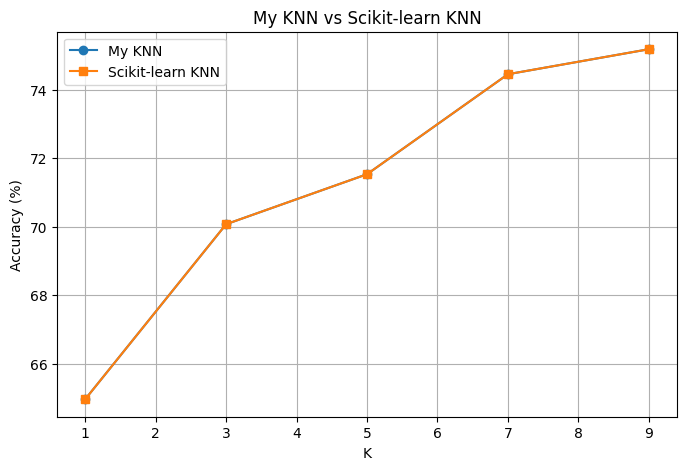

In [81]:
# A8 - Accuracy comparison graph

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    my_accuracy,
    marker="o",
    label="My KNN"
)

plt.plot(
    k_values,
    sklearn_accuracy,
    marker="s",
    label="Scikit-learn KNN"
)

plt.xlabel("K")
plt.ylabel("Accuracy (%)")
plt.title("My KNN vs Scikit-learn KNN")

plt.legend()
plt.grid()

plt.show()

In [82]:
# A9 - Weighted class assignment

def weighted_class(neighbors):

    votes = {}

    for distance, label in neighbors:

        if distance == 0:
            weight = float("inf")
        else:
            weight = 1 / distance

        if label not in votes:
            votes[label] = 0

        votes[label] += weight

    return max(
        votes,
        key=votes.get
    )

In [83]:
# A9 - Weighted KNN

weighted_predictions = []

for point in X_test:

    neighbors = identify_neighbors(
        X_train,
        y_train,
        point,
        k=3
    )

    prediction = weighted_class(
        neighbors
    )

    weighted_predictions.append(
        prediction
    )

weighted_predictions = np.array(
    weighted_predictions
)

weighted_accuracy = np.mean(
    weighted_predictions == y_test
)

print(
    "Weighted KNN Accuracy:",
    weighted_accuracy * 100,
    "%"
)

Weighted KNN Accuracy: 70.07299270072993 %


In [84]:
# Compare normal KNN and weighted KNN

print(
    "Normal KNN Accuracy:",
    my_accuracy * 100,
    "%"
)

print(
    "Weighted KNN Accuracy:",
    weighted_accuracy * 100,
    "%"
)

Normal KNN Accuracy: [np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481), np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481), np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481), np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481), np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481), np.float64(64.96350364963503), np.float64(70.07299270072993), np.float64(71.53284671532847), np.float64(74.45255474452554), np.float64(75.18248175182481), np.float64(64.96350364963503), np.float64(70.072